# Data Cleaning and Preprocessing — Adult Census Income

This notebook performs data cleaning and preprocessing on the Adult Census Income dataset.

### Workflow
1. Load and inspect the dataset
2. Check data types and missing values
3. Handle missing values and inconsistent entries
4. Encode categorical variables
5. Standardize numerical features
6. Detect and remove outliers using the IQR method
7. Save the processed dataset and visualization


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", None)
sns.set_style("whitegrid")

print("Libraries imported successfully.")


Libraries imported successfully.


In [2]:
# Locate the dataset relative to this notebook.
# Expected project structure:
# project/
# ├── dataset/adult.csv
# └── notebooks/data_preprocessing.ipynb

DATA_PATH = "D:\\Day-1-task-Elevate-Lab---Nishita-kanojiya\\Dataset 2 - Adult\\dataset\\adult.csv"
OUTPUT_DIR = "D:\\Day-1-task-Elevate-Lab---Nishita-kanojiya\\Dataset 2 - Adult\\outputs"

os.makedirs(OUTPUT_DIR, exist_ok=True)

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Dataset path:", DATA_PATH)


Dataset loaded successfully.
Dataset path: D:\Day-1-task-Elevate-Lab---Nishita-kanojiya\Dataset 2 - Adult\dataset\adult.csv


In [3]:
df.head()


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [4]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
print("Shape:", df.shape)


Rows: 48842
Columns: 15
Shape: (48842, 15)


In [5]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 48842 entries, 0 to 48841
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   age             48842 non-null  int64
 1   workclass       47879 non-null  str  
 2   fnlwgt          48842 non-null  int64
 3   education       48842 non-null  str  
 4   education-num   48842 non-null  int64
 5   marital-status  48842 non-null  str  
 6   occupation      47876 non-null  str  
 7   relationship    48842 non-null  str  
 8   race            48842 non-null  str  
 9   sex             48842 non-null  str  
 10  capital-gain    48842 non-null  int64
 11  capital-loss    48842 non-null  int64
 12  hours-per-week  48842 non-null  int64
 13  native-country  48568 non-null  str  
 14  income          48842 non-null  str  
dtypes: int64(6), str(9)
memory usage: 5.6 MB


In [6]:
df.describe(include="all").T


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,48842.0,NaN,NaN,NaN,38.643585,13.71051,17.0,28.0,37.0,48.0,90.0
workclass,47879,9,Private,33906,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fnlwgt,48842.0,NaN,NaN,NaN,189664.134597,105604.025423,12285.0,117550.5,178144.5,237642.0,1490400.0
education,48842,16,HS-grad,15784,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education-num,48842.0,NaN,NaN,NaN,10.078089,2.570973,1.0,9.0,10.0,12.0,16.0
marital-status,48842,7,Married-civ-spouse,22379,NaN,NaN,NaN,NaN,NaN,NaN,NaN
occupation,47876,15,Prof-specialty,6172,NaN,NaN,NaN,NaN,NaN,NaN,NaN
relationship,48842,6,Husband,19716,NaN,NaN,NaN,NaN,NaN,NaN,NaN
race,48842,5,White,41762,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,48842,2,Male,32650,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
print("Columns:")
print(df.columns.tolist())


Columns:
['age', 'workclass', 'fnlwgt', 'education', 'education-num', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income']


## 1. Missing Values and Inconsistent Entries

The Adult dataset may contain missing values represented by `?`. These values are treated as missing data before preprocessing.


In [8]:
print("Missing values represented by '?':")
question_marks = (df == "?").sum()
print(question_marks[question_marks > 0])


Missing values represented by '?':
workclass         1836
occupation        1843
native-country     583
dtype: int64


In [9]:
# Convert '?' to NaN
df = df.replace("?", np.nan)

print("'?' values converted to NaN.")


'?' values converted to NaN.


In [10]:
missing_values = df.isnull().sum()
missing_percentage = (df.isnull().sum() / len(df) * 100).round(2)

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": missing_percentage
})

print(missing_summary[missing_summary["Missing Values"] > 0])


                Missing Values  Missing Percentage
workclass                 2799                5.73
occupation                2809                5.75
native-country             857                1.75


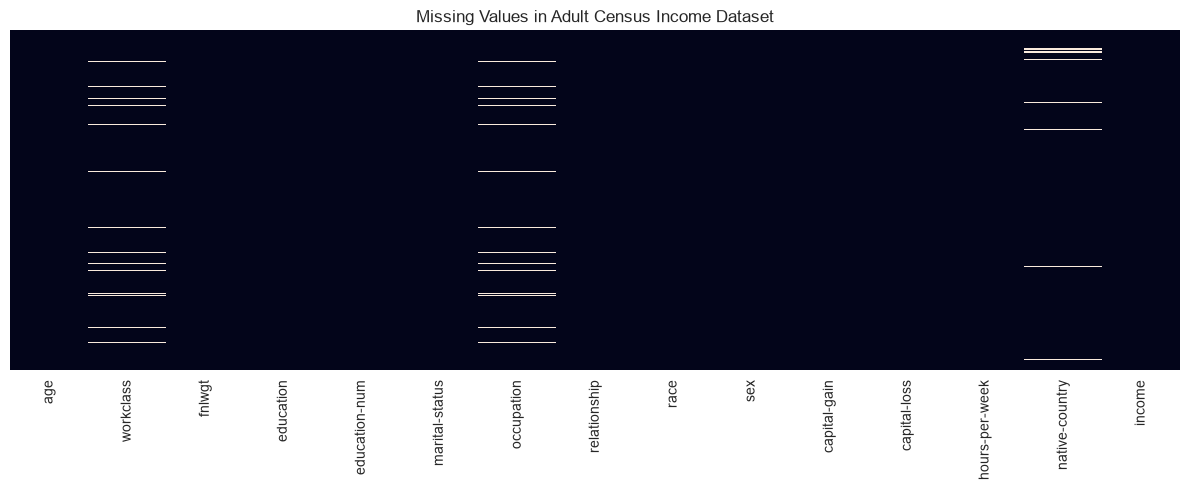

In [11]:
plt.figure(figsize=(12, 5))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False
)

plt.title("Missing Values in Adult Census Income Dataset")
plt.tight_layout()
plt.show()


In [12]:
numerical_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Numerical columns:")
print(numerical_columns)

print("\nCategorical columns:")
print(categorical_columns)


Numerical columns:
['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

Categorical columns:
['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country', 'income']


C:\Users\Nishita\AppData\Local\Temp\ipykernel_16228\3013482269.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


## 2. Handle Missing Values

- Numerical columns → median
- Categorical columns → mode


In [13]:
for column in numerical_columns:
    df[column] = df[column].fillna(df[column].median())

for column in categorical_columns:
    df[column] = df[column].fillna(df[column].mode()[0])

print("Missing values handled successfully.")


Missing values handled successfully.


In [14]:
print("Total remaining missing values:", df.isnull().sum().sum())


Total remaining missing values: 0


In [15]:
print("Categorical value counts:")

for column in categorical_columns:
    print(f"\n--- {column} ---")
    print(df[column].value_counts().head(10))


Categorical value counts:

--- workclass ---
workclass
Private             36705
Self-emp-not-inc     3862
Local-gov            3136
State-gov            1981
Self-emp-inc         1695
Federal-gov          1432
Without-pay            21
Never-worked           10
Name: count, dtype: int64

--- education ---
education
HS-grad         15784
Some-college    10878
Bachelors        8025
Masters          2657
Assoc-voc        2061
11th             1812
Assoc-acdm       1601
10th             1389
7th-8th           955
Prof-school       834
Name: count, dtype: int64

--- marital-status ---
marital-status
Married-civ-spouse       22379
Never-married            16117
Divorced                  6633
Separated                 1530
Widowed                   1518
Married-spouse-absent      628
Married-AF-spouse           37
Name: count, dtype: int64

--- occupation ---
occupation
Prof-specialty       8981
Craft-repair         6112
Exec-managerial      6086
Adm-clerical         5611
Sales              

## 3. Encode the Target Variable

The target column is `income`.

- `<=50K` → `0`
- `>50K` → `1`


In [16]:
# Clean possible whitespace around target values
df["income"] = df["income"].astype(str).str.strip()

print(df["income"].value_counts())


income
<=50K     24720
<=50K.    12435
>50K       7841
>50K.      3846
Name: count, dtype: int64


In [17]:
df["income"] = df["income"].map({
    "<=50K": 0,
    ">50K": 1
})

print("Target variable encoded successfully.")
print(df["income"].value_counts())


Target variable encoded successfully.
income
0.0    24720
1.0     7841
Name: count, dtype: int64


## 4. Encode Categorical Features

Categorical predictor columns are converted into numerical features using one-hot encoding.

`drop_first=True` is used to avoid redundant dummy variables.


In [18]:
# Identify categorical predictor columns only
categorical_columns = df.select_dtypes(
    include=["object", "category"]
).columns.tolist()

print("Categorical columns to encode:")
print(categorical_columns)


Categorical columns to encode:
['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']


C:\Users\Nishita\AppData\Local\Temp\ipykernel_16228\126755821.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(


In [19]:
df = pd.get_dummies(
    df,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

print("Categorical variables encoded successfully.")
print("New dataset shape:", df.shape)


Categorical variables encoded successfully.
New dataset shape: (48842, 98)


In [20]:
df.head()


,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week,income,workclass_Local-gov,workclass_Never-worked,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,workclass_State-gov,workclass_Without-pay,education_11th,education_12th,education_1st-4th,education_5th-6th,education_7th-8th,education_9th,education_Assoc-acdm,education_Assoc-voc,education_Bachelors,education_Doctorate,education_HS-grad,education_Masters,education_Preschool,education_Prof-school,education_Some-college,marital-status_Married-AF-spouse,marital-status_Married-civ-spouse,marital-status_Married-spouse-absent,marital-status_Never-married,marital-status_Separated,marital-status_Widowed,occupation_Armed-Forces,occupation_Craft-repair,occupation_Exec-managerial,occupation_Farming-fishing,occupation_Handlers-cleaners,occupation_Machine-op-inspct,occupation_Other-service,occupation_Priv-house-serv,occupation_Prof-specialty,occupation_Protective-serv,occupation_Sales,occupation_Tech-support,occupation_Transport-moving,relationship_Not-in-family,relationship_Other-relative,relationship_Own-child,relationship_Unmarried,relationship_Wife,race_Asian-Pac-Islander,race_Black,race_Other,race_White,sex_Male,native-country_Canada,native-country_China,native-country_Columbia,native-country_Cuba,native-country_Dominican-Republic,native-country_Ecuador,native-country_El-Salvador,native-country_England,native-country_France,native-country_Germany,native-country_Greece,native-country_Guatemala,native-country_Haiti,native-country_Holand-Netherlands,native-country_Honduras,native-country_Hong,native-country_Hungary,native-country_India,native-country_Iran,native-country_Ireland,native-country_Italy,native-country_Jamaica,native-country_Japan,native-country_Laos,native-country_Mexico,native-country_Nicaragua,native-country_Outlying-US(Guam-USVI-etc),native-country_Peru,native-country_Philippines,native-country_Poland,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
0,39,77516,13,2174,0,40,0.0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
1,50,83311,13,0,0,13,0.0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
2,38,215646,9,0,0,40,0.0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
3,53,234721,7,0,0,40,0.0,0,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0
4,28,338409,13,0,0,40,0.0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [21]:
print(df.dtypes.value_counts())


int64      97
float64     1
Name: count, dtype: int64


## 5. Standardize Numerical Features

`StandardScaler` transforms numerical features so that they have approximately:

- Mean = 0
- Standard deviation = 1

The target variable `income` is not standardized.


In [22]:
numerical_columns = df.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

if "income" in numerical_columns:
    numerical_columns.remove("income")

print("Numerical features to standardize:")
print(numerical_columns)


Numerical features to standardize:
['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week', 'workclass_Local-gov', 'workclass_Never-worked', 'workclass_Private', 'workclass_Self-emp-inc', 'workclass_Self-emp-not-inc', 'workclass_State-gov', 'workclass_Without-pay', 'education_11th', 'education_12th', 'education_1st-4th', 'education_5th-6th', 'education_7th-8th', 'education_9th', 'education_Assoc-acdm', 'education_Assoc-voc', 'education_Bachelors', 'education_Doctorate', 'education_HS-grad', 'education_Masters', 'education_Preschool', 'education_Prof-school', 'education_Some-college', 'marital-status_Married-AF-spouse', 'marital-status_Married-civ-spouse', 'marital-status_Married-spouse-absent', 'marital-status_Never-married', 'marital-status_Separated', 'marital-status_Widowed', 'occupation_Armed-Forces', 'occupation_Craft-repair', 'occupation_Exec-managerial', 'occupation_Farming-fishing', 'occupation_Handlers-cleaners', 'occupation_Machine-op-inspct', 'occ

In [23]:
scaler = StandardScaler()

df[numerical_columns] = scaler.fit_transform(
    df[numerical_columns]
)

print("Numerical features standardized successfully.")


Numerical features standardized successfully.


In [24]:
df[numerical_columns].describe().T


,count,mean,std,min,25%,50%,75%,max
age,48842.0,2.286911e-16,1.00001,-1.578629,-0.776316,-0.119879,0.682433,3.745808
fnlwgt,48842.0,-5.717278e-17,1.00001,-1.679680,-0.682875,-0.109084,0.454323,12.317231
education-num,48842.0,-9.136007e-17,1.00001,-3.531030,-0.419335,-0.030373,0.747550,2.303397
capital-gain,48842.0,1.760282e-17,1.00001,-0.144804,-0.144804,-0.144804,-0.144804,13.274382
capital-loss,48842.0,-7.564846e-18,1.00001,-0.217127,-0.217127,-0.217127,-0.217127,10.591794
...,...,...,...,...,...,...,...,...
native-country_Thailand,48842.0,2.182167e-18,1.00001,-0.024791,-0.024791,-0.024791,-0.024791,40.336914
native-country_Trinadad&Tobago,48842.0,9.892491e-18,1.00001,-0.023518,-0.023518,-0.023518,-0.023518,42.520148
native-country_United-States,48842.0,-4.538908e-17,1.00001,-3.280344,0.304846,0.304846,0.304846,0.304846
native-country_Vietnam,48842.0,-1.163823e-17,1.00001,-0.041999,-0.041999,-0.041999,-0.041999,23.810297


## 6. Detect Outliers Using Boxplots


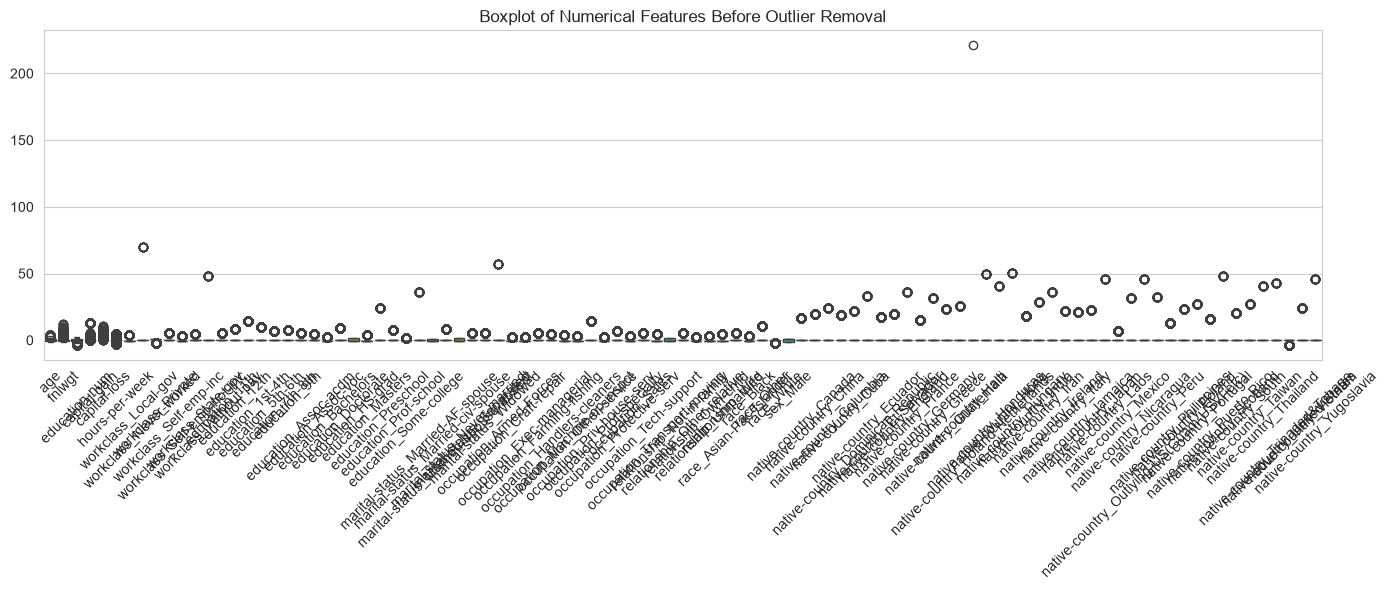

In [25]:
plt.figure(figsize=(14, 6))

sns.boxplot(data=df[numerical_columns])

plt.title("Boxplot of Numerical Features Before Outlier Removal")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [26]:
Q1 = df[numerical_columns].quantile(0.25)
Q3 = df[numerical_columns].quantile(0.75)

IQR = Q3 - Q1

print("IQR calculated successfully.")


IQR calculated successfully.


In [27]:
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

bounds = pd.DataFrame({
    "Lower Bound": lower_bound,
    "Upper Bound": upper_bound
})

bounds


,Lower Bound,Upper Bound
age,-2.964441,2.870558
fnlwgt,-2.388673,2.160121
education-num,-2.169663,2.497878
capital-gain,-0.144804,-0.144804
capital-loss,-0.217127,-0.217127
...,...,...
native-country_Thailand,-0.024791,-0.024791
native-country_Trinadad&Tobago,-0.023518,-0.023518
native-country_United-States,0.304846,0.304846
native-country_Vietnam,-0.041999,-0.041999


In [28]:
outlier_counts = (
    (df[numerical_columns] < lower_bound) |
    (df[numerical_columns] > upper_bound)
).sum()

print("Outliers in each numerical feature:")
print(outlier_counts)


Outliers in each numerical feature:
age                                216
fnlwgt                            1453
education-num                     1794
capital-gain                      4035
capital-loss                      2282
                                  ... 
native-country_Thailand             30
native-country_Trinadad&Tobago      27
native-country_United-States      4153
native-country_Vietnam              86
native-country_Yugoslavia           23
Length: 97, dtype: int64


## 7. Remove Outliers

Rows containing an outlier in any selected numerical feature are removed using the IQR rule.

The target variable is excluded from outlier detection.


In [29]:
outlier_condition = (
    (df[numerical_columns] < lower_bound) |
    (df[numerical_columns] > upper_bound)
).any(axis=1)

df_cleaned = df.loc[~outlier_condition].copy()

print("Original shape:", df.shape)
print("Cleaned shape:", df_cleaned.shape)
print("Rows removed:", len(df) - len(df_cleaned))


Original shape: (48842, 98)
Cleaned shape: (422, 98)
Rows removed: 48420


In [30]:
print("Remaining missing values:", df_cleaned.isnull().sum().sum())


Remaining missing values: 141


In [31]:
df_cleaned.head()


,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week,income,workclass_Local-gov,workclass_Never-worked,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,workclass_State-gov,workclass_Without-pay,education_11th,education_12th,education_1st-4th,education_5th-6th,education_7th-8th,education_9th,education_Assoc-acdm,education_Assoc-voc,education_Bachelors,education_Doctorate,education_HS-grad,education_Masters,education_Preschool,education_Prof-school,education_Some-college,marital-status_Married-AF-spouse,marital-status_Married-civ-spouse,marital-status_Married-spouse-absent,marital-status_Never-married,marital-status_Separated,marital-status_Widowed,occupation_Armed-Forces,occupation_Craft-repair,occupation_Exec-managerial,occupation_Farming-fishing,occupation_Handlers-cleaners,occupation_Machine-op-inspct,occupation_Other-service,occupation_Priv-house-serv,occupation_Prof-specialty,occupation_Protective-serv,occupation_Sales,occupation_Tech-support,occupation_Transport-moving,relationship_Not-in-family,relationship_Other-relative,relationship_Own-child,relationship_Unmarried,relationship_Wife,race_Asian-Pac-Islander,race_Black,race_Other,race_White,sex_Male,native-country_Canada,native-country_China,native-country_Columbia,native-country_Cuba,native-country_Dominican-Republic,native-country_Ecuador,native-country_El-Salvador,native-country_England,native-country_France,native-country_Germany,native-country_Greece,native-country_Guatemala,native-country_Haiti,native-country_Holand-Netherlands,native-country_Honduras,native-country_Hong,native-country_Hungary,native-country_India,native-country_Iran,native-country_Ireland,native-country_Italy,native-country_Jamaica,native-country_Japan,native-country_Laos,native-country_Mexico,native-country_Nicaragua,native-country_Outlying-US(Guam-USVI-etc),native-country_Peru,native-country_Philippines,native-country_Poland,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
58,0.171871,-0.400483,-0.419335,-0.144804,-0.217127,0.611526,0.0,-0.26194,-0.01431,0.575033,-0.189609,-0.293019,-0.205606,-0.02074,-0.196287,-0.116769,-0.071294,-0.102621,-0.141219,-0.125387,-0.184093,-0.209896,-0.443406,-0.110957,1.447204,-0.239853,-0.041258,-0.131803,-0.535289,-0.027534,1.087425,-0.114128,-0.701782,-0.179829,-0.1791,-0.017527,-0.378203,-0.377283,-0.177388,-0.21048,-0.256815,-0.334803,-0.070565,-0.474666,-0.143316,-0.356373,-0.174668,-0.225076,-0.589093,-0.178368,-0.428641,-0.342391,-0.223869,-0.179161,-0.325728,-0.091554,0.411743,0.70422,-0.061157,-0.050041,-0.041753,-0.05323,-0.045971,-0.030368,-0.056423,-0.051059,-0.027904,-0.065081,-0.03169,-0.042485,-0.039216,-0.004525,-0.02024,-0.024791,-0.019727,-0.055688,-0.034777,-0.027534,-0.046416,-0.046637,-0.043442,-0.021705,-0.140917,-0.03169,-0.021705,-0.030703,-0.077952,-0.042243,-0.037063,-0.061494,-0.02074,-0.048581,-0.036505,-0.024791,-0.023518,0.304846,-0.041999,-0.021705
151,-0.338691,0.080669,-0.419335,-0.144804,-0.217127,-0.034087,0.0,-0.26194,-0.01431,0.575033,-0.189609,-0.293019,-0.205606,-0.02074,-0.196287,-0.116769,-0.071294,-0.102621,-0.141219,-0.125387,-0.184093,-0.209896,-0.443406,-0.110957,1.447204,-0.239853,-0.041258,-0.131803,-0.535289,-0.027534,-0.919604,-0.114128,1.424944,-0.179829,-0.1791,-0.017527,-0.378203,-0.377283,-0.177388,-0.21048,-0.256815,-0.334803,-0.070565,-0.474666,-0.143316,-0.356373,-0.174668,-0.225076,1.697524,-0.178368,-0.428641,-0.342391,-0.223869,-0.179161,-0.325728,-0.091554,0.411743,-1.42001,-0.061157,-0.050041,-0.041753,-0.05323,-0.045971,-0.030368,-0.056423,-0.051059,-0.027904,-0.065081,-0.03169,-0.042485,-0.039216,-0.004525,-0.02024,-0.024791,-0.019727,-0.055688,-0.034777,-0.027534,-0.046416,-0.046637,-0.043442,-0.021705,-0.140917,-0.03169,-0.021705,-0.030703,-0.077952,-0.042243,-0.037063

## 8. Final Boxplot


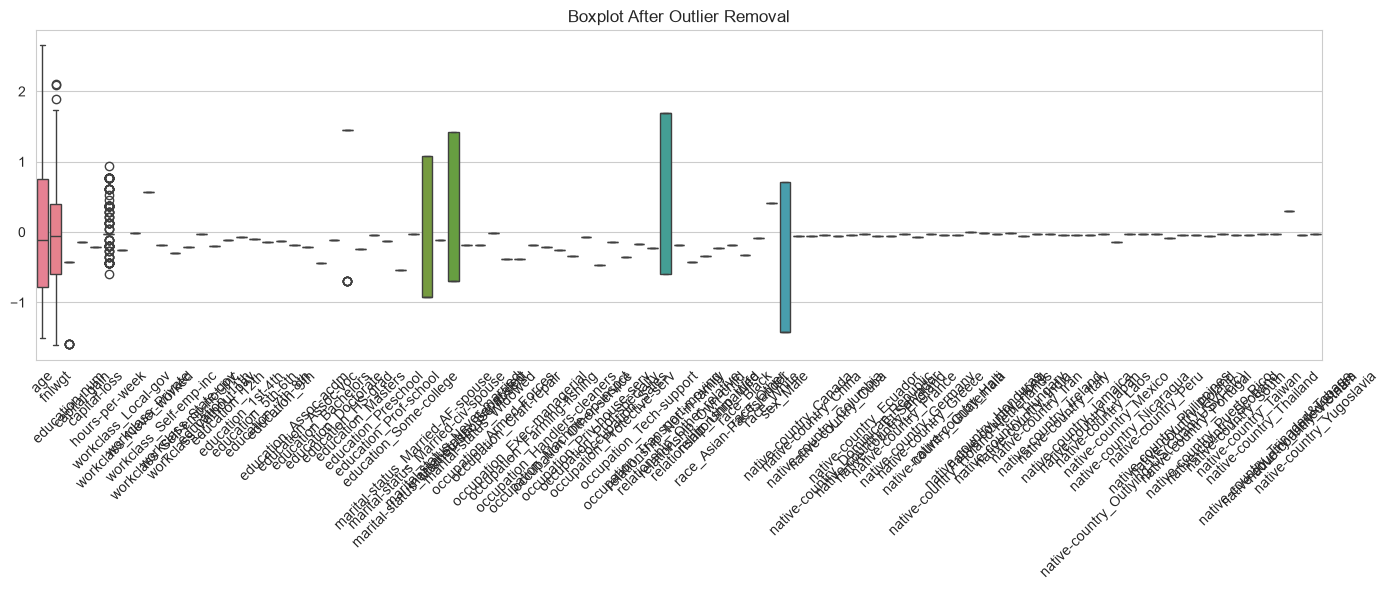

Final boxplot saved to: D:\Day-1-task-Elevate-Lab---Nishita-kanojiya\Dataset 2 - Adult\outputs\final_boxplot.png


In [32]:
plt.figure(figsize=(14, 6))

sns.boxplot(data=df_cleaned[numerical_columns])

plt.title("Boxplot After Outlier Removal")
plt.xticks(rotation=45)
plt.tight_layout()

final_boxplot_path = os.path.join(
    OUTPUT_DIR,
    "final_boxplot.png"
)

plt.savefig(
    final_boxplot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Final boxplot saved to:", final_boxplot_path)


## 9. Save the Cleaned Dataset


In [33]:
cleaned_dataset_path = os.path.join(
    OUTPUT_DIR,
    "cleaned_adult.csv"
)

df_cleaned.to_csv(
    cleaned_dataset_path,
    index=False
)

print("Cleaned dataset saved successfully.")
print("File:", cleaned_dataset_path)


Cleaned dataset saved successfully.
File: D:\Day-1-task-Elevate-Lab---Nishita-kanojiya\Dataset 2 - Adult\outputs\cleaned_adult.csv


In [34]:
print("========== FINAL DATASET VERIFICATION ==========")

print("\nShape:")
print(df_cleaned.shape)

print("\nMissing values:")
print(df_cleaned.isnull().sum().sum())

print("\nData types:")
print(df_cleaned.dtypes.value_counts())

print("\nFirst 5 rows:")
display(df_cleaned.head())


========== FINAL DATASET VERIFICATION ==========

Shape:
(422, 98)

Missing values:
141

Data types:
float64    98
Name: count, dtype: int64

First 5 rows:


,age,fnlwgt,education-num,capital-gain,capital-loss,hours-per-week,income,workclass_Local-gov,workclass_Never-worked,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,workclass_State-gov,workclass_Without-pay,education_11th,education_12th,education_1st-4th,education_5th-6th,education_7th-8th,education_9th,education_Assoc-acdm,education_Assoc-voc,education_Bachelors,education_Doctorate,education_HS-grad,education_Masters,education_Preschool,education_Prof-school,education_Some-college,marital-status_Married-AF-spouse,marital-status_Married-civ-spouse,marital-status_Married-spouse-absent,marital-status_Never-married,marital-status_Separated,marital-status_Widowed,occupation_Armed-Forces,occupation_Craft-repair,occupation_Exec-managerial,occupation_Farming-fishing,occupation_Handlers-cleaners,occupation_Machine-op-inspct,occupation_Other-service,occupation_Priv-house-serv,occupation_Prof-specialty,occupation_Protective-serv,occupation_Sales,occupation_Tech-support,occupation_Transport-moving,relationship_Not-in-family,relationship_Other-relative,relationship_Own-child,relationship_Unmarried,relationship_Wife,race_Asian-Pac-Islander,race_Black,race_Other,race_White,sex_Male,native-country_Canada,native-country_China,native-country_Columbia,native-country_Cuba,native-country_Dominican-Republic,native-country_Ecuador,native-country_El-Salvador,native-country_England,native-country_France,native-country_Germany,native-country_Greece,native-country_Guatemala,native-country_Haiti,native-country_Holand-Netherlands,native-country_Honduras,native-country_Hong,native-country_Hungary,native-country_India,native-country_Iran,native-country_Ireland,native-country_Italy,native-country_Jamaica,native-country_Japan,native-country_Laos,native-country_Mexico,native-country_Nicaragua,native-country_Outlying-US(Guam-USVI-etc),native-country_Peru,native-country_Philippines,native-country_Poland,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
58,0.171871,-0.400483,-0.419335,-0.144804,-0.217127,0.611526,0.0,-0.26194,-0.01431,0.575033,-0.189609,-0.293019,-0.205606,-0.02074,-0.196287,-0.116769,-0.071294,-0.102621,-0.141219,-0.125387,-0.184093,-0.209896,-0.443406,-0.110957,1.447204,-0.239853,-0.041258,-0.131803,-0.535289,-0.027534,1.087425,-0.114128,-0.701782,-0.179829,-0.1791,-0.017527,-0.378203,-0.377283,-0.177388,-0.21048,-0.256815,-0.334803,-0.070565,-0.474666,-0.143316,-0.356373,-0.174668,-0.225076,-0.589093,-0.178368,-0.428641,-0.342391,-0.223869,-0.179161,-0.325728,-0.091554,0.411743,0.70422,-0.061157,-0.050041,-0.041753,-0.05323,-0.045971,-0.030368,-0.056423,-0.051059,-0.027904,-0.065081,-0.03169,-0.042485,-0.039216,-0.004525,-0.02024,-0.024791,-0.019727,-0.055688,-0.034777,-0.027534,-0.046416,-0.046637,-0.043442,-0.021705,-0.140917,-0.03169,-0.021705,-0.030703,-0.077952,-0.042243,-0.037063,-0.061494,-0.02074,-0.048581,-0.036505,-0.024791,-0.023518,0.304846,-0.041999,-0.021705
151,-0.338691,0.080669,-0.419335,-0.144804,-0.217127,-0.034087,0.0,-0.26194,-0.01431,0.575033,-0.189609,-0.293019,-0.205606,-0.02074,-0.196287,-0.116769,-0.071294,-0.102621,-0.141219,-0.125387,-0.184093,-0.209896,-0.443406,-0.110957,1.447204,-0.239853,-0.041258,-0.131803,-0.535289,-0.027534,-0.919604,-0.114128,1.424944,-0.179829,-0.1791,-0.017527,-0.378203,-0.377283,-0.177388,-0.21048,-0.256815,-0.334803,-0.070565,-0.474666,-0.143316,-0.356373,-0.174668,-0.225076,1.697524,-0.178368,-0.428641,-0.342391,-0.223869,-0.179161,-0.325728,-0.091554,0.411743,-1.42001,-0.061157,-0.050041,-0.041753,-0.05323,-0.045971,-0.030368,-0.056423,-0.051059,-0.027904,-0.065081,-0.03169,-0.042485,-0.039216,-0.004525,-0.02024,-0.024791,-0.019727,-0.055688,-0.034777,-0.027534,-0.046416,-0.046637,-0.043442,-0.021705,-0.140917,-0.03169,-0.021705,-0.030703,-0.077952,-0.042243,-0.037063

# Conclusion

The Adult Census Income dataset was successfully cleaned and preprocessed.

The workflow included:

- Dataset inspection
- Detection of missing and inconsistent values
- Missing-value handling using median and mode
- Encoding of categorical variables
- Target-variable encoding
- Standardization of numerical features
- Outlier detection using the IQR method
- Outlier removal
- Saving the cleaned dataset
- Saving the final boxplot

The processed dataset is ready for further machine learning analysis and model development.
